1. Library Imports and Reproducibility
This section imports essential libraries for data manipulation (pandas, numpy), machine learning (tensorflow, keras), and plotting (matplotlib.pyplot). A random seed is also set to ensure that the results are reproducible.

In [1]:
import tensorflow as tf
from tensorflow import keras
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
keras.utils.set_random_seed(42)

2. Data Loading
Here, the heart disease dataset is loaded from a specified URL into a pandas DataFrame. This DataFrame will be the basis for all subsequent data preprocessing and model training.

In [3]:
df = pd.read_csv("http://storage.googleapis.com/download.tensorflow.org/data/heart.csv")

3. Initial Data Inspection
We display the first few rows of the DataFrame and check its overall shape to understand the structure of the loaded data, including the number of rows and columns.

In [4]:
df

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,1,145,233,1,2,150,0,2.3,3,0,fixed,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3,normal,1
2,67,1,4,120,229,0,2,129,1,2.6,2,2,reversible,0
3,37,1,3,130,250,0,0,187,0,3.5,3,0,normal,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0,normal,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
298,52,1,1,118,186,0,2,190,0,0.0,2,0,fixed,0
299,43,0,4,132,341,1,2,136,1,3.0,2,0,reversible,1
300,65,1,4,135,254,0,2,127,0,2.8,2,1,reversible,1
301,48,1,4,130,256,1,2,150,1,0.0,1,2,reversible,1


In [5]:
df.shape

(303, 14)

In [6]:
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,1,145,233,1,2,150,0,2.3,3,0,fixed,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3,normal,1
2,67,1,4,120,229,0,2,129,1,2.6,2,2,reversible,0
3,37,1,3,130,250,0,0,187,0,3.5,3,0,normal,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0,normal,0


4. Target Variable Distribution
This step analyzes the distribution of the 'target' variable. This is crucial for classification tasks to identify if there's a class imbalance that might require special handling later.

In [7]:
df.target.value_counts(normalize=True, dropna=False)

,proportion
target,
0,0.726073
1,0.273927


5. Feature Separation
Here, we define which columns are categorical and which are numerical. This separation is necessary because different types of features often require different preprocessing steps.

In [8]:
categorical_variables = ['sex', 'cp', 'fbs', 'restecg', 'exang', 'ca', 'thal']
numerics = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak', 'slope']

6. One-Hot Encoding for Categorical Variables
Categorical variables need to be converted into a numerical format that machine learning models can understand. One-hot encoding creates new binary columns for each category, which is suitable for our neural network model.

In [9]:
df = pd.get_dummies(df, columns = categorical_variables, dtype=np.int32)

In [10]:
df.head()

,age,trestbps,chol,thalach,oldpeak,slope,target,sex_0,sex_1,cp_0,...,exang_1,ca_0,ca_1,ca_2,ca_3,thal_1,thal_2,thal_fixed,thal_normal,thal_reversible
0,63,145,233,150,2.3,3,0,0,1,0,...,0,1,0,0,0,0,0,1,0,0
1,67,160,286,108,1.5,2,1,0,1,0,...,1,0,0,0,1,0,0,0,1,0
2,67,120,229,129,2.6,2,0,0,1,0,...,1,0,0,1,0,0,0,0,0,1
3,37,130,250,187,3.5,3,0,0,1,0,...,0,1,0,0,0,0,0,0,1,0
4,41,130,204,172,1.4,1,0,1,0,0,...,0,1,0,0,0,0,0,0,1,0


7. Data Splitting (Train and Test Sets)
To properly evaluate our model's performance on unseen data, the dataset is split into training (80%) and testing (20%) sets. A random_state is used for reproducibility of the split.

In [11]:
test_df = df.sample(frac=0.2, random_state=42)
train_df = df.drop(test_df.index)

8. Shape of Training and Test DataFrames
We verify the number of rows and columns in the training and testing DataFrames after splitting to ensure the split was performed correctly.

In [12]:
train_df.shape

(242, 30)

In [13]:
test_df.shape

(61, 30)

9. Numerical Feature Standardization
Neural networks often perform better when input features are scaled. Here, numerical features are standardized (mean-centered and scaled by standard deviation) using only the training data statistics to prevent data leakage from the test set.

In [14]:
means = train_df[numerics].mean()
sd = train_df[numerics].std()

In [15]:
means

,0
age,54.268595
trestbps,131.995868
chol,246.512397
thalach,149.805785
oldpeak,1.032645
slope,1.590909


In [16]:
train_df[numerics] = (train_df[numerics] - means)/sd

In [17]:
test_df[numerics] = (test_df[numerics] - means)/sd

In [18]:
train_df.head()

,age,trestbps,chol,thalach,oldpeak,slope,target,sex_0,sex_1,cp_0,...,exang_1,ca_0,ca_1,ca_2,ca_3,thal_1,thal_2,thal_fixed,thal_normal,thal_reversible
0,0.963746,0.721939,-0.278690,0.008396,1.083461,2.226814,0,0,1,0,...,0,1,0,0,0,0,0,1,0,0
1,1.405254,1.554681,0.814423,-1.807247,0.399542,0.646494,1,0,1,0,...,1,0,0,0,1,0,0,0,1,0
2,1.405254,-0.665964,-0.361189,-0.899426,1.339930,0.646494,0,0,1,0,...,1,0,0,1,0,0,0,0,0,1
3,-1.906055,-0.110803,0.071931,1.607891,2.109339,2.226814,0,0,1,0,...,0,1,0,0,0,0,0,0,1,0
4,-1.464547,-0.110803,-0.876809,0.959447,0.314052,-0.933825,0,1,0,0,...,0,1,0,0,0,0,0,0,1,0


10. Converting DataFrames to NumPy Arrays
Keras models typically expect NumPy arrays as input. This step converts the preprocessed training and testing DataFrames into NumPy arrays.

In [19]:
train = train_df.to_numpy()
test = test_df.to_numpy()

11. Separating Features (X) and Target (y)
We separate the features (train_X, test_X) from the target variable (train_y, test_y). In this dataset, the 'target' column is at index 6 after one-hot encoding.

In [20]:
train_X = np.delete(train, 6, axis=1)
test_X = np.delete(test, 6, axis=1)

In [21]:
train_X.shape, test_X.shape

((242, 29), (61, 29))

In [22]:
train_y = train[:, 6]
test_y = test[:, 6]

In [24]:
train_y.shape, test_y.shape

((242,), (61,))

12. Model Definition (Baseline Neural Network)
This section defines our baseline neural network model using Keras. It's a simple feedforward network with one hidden layer (16 neurons, ReLU activation) and an output layer (1 neuron, sigmoid activation) suitable for binary classification.

In [29]:
num_colums = train_X.shape[1]

input = keras.layers.Input(shape=(num_colums,))

h = keras.layers.Dense(16, activation='relu', name="Hidden")(input)

output = keras.layers.Dense(1, activation='sigmoid', name="Output")(h)

model = keras.Model(inputs=input, outputs=output)

13. Model Summary and Visualization
The model.summary() provides a text-based overview of the model's layers, output shapes, and parameter count. keras.utils.plot_model offers a visual representation of the network architecture.

In [30]:
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 29)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Hidden (Dense)                  │ (None, 16)             │           480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Output (Dense)                  │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 497 (1.94 KB)

 Trainable params: 497 (1.94 KB)

 Non-trainable params: 0 (0.00 B)

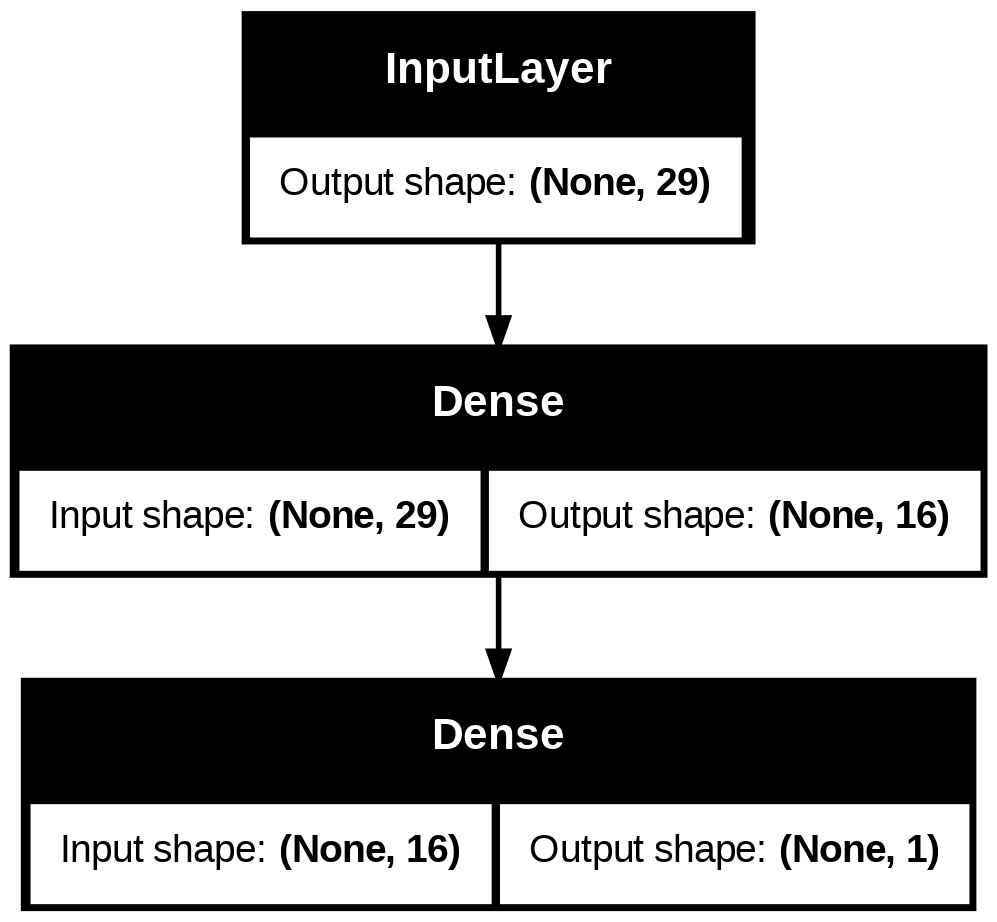

In [31]:
keras.utils.plot_model(model, show_shapes=True)

14. Model Compilation
Before training, the model needs to be compiled. We specify the adam optimizer, binary_crossentropy as the loss function (standard for binary classification), and accuracy as the metric to monitor.

In [32]:
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

15. Model Training (Baseline)
Here, the model is trained on the train_X and train_y data for 300 epochs. A validation split of 20% is used to monitor performance on unseen data during training and detect overfitting.

In [33]:
history = model.fit(train_X, train_y, epochs=300, batch_size=32, verbose=1, validation_split=0.2)

Epoch 1/300
7/7 ━━━━━━━━━━━━━━━━━━━━ 3s 162ms/step - accuracy: 0.5742 - loss: 0.6878 - val_accuracy: 0.5102 - val_loss: 0.7111
Epoch 2/300
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.6269 - loss: 0.6390 - val_accuracy: 0.5918 - val_loss: 0.6852
Epoch 3/300
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.6908 - loss: 0.6024 - val_accuracy: 0.5714 - val_loss: 0.6636
Epoch 4/300
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.7115 - loss: 0.5718 - val_accuracy: 0.5918 - val_loss: 0.6450
Epoch 5/300
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.7393 - loss: 0.5456 - val_accuracy: 0.6122 - val_loss: 0.6292
Epoch 6/300
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.7622 - loss: 0.5229 - val_accuracy: 0.6735 - val_loss: 0.6155
Epoch 7/300
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.7782 - loss: 0.5030 - val_accuracy: 0.6531 - val_loss: 0.6035
Epoch 8/300
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.7851 - loss: 0.4856 - val_accuracy: 0.6531 - val_loss

16. Accessing Training History
The history object returned by model.fit() contains a dictionary (history_dict) with the training and validation metrics recorded per epoch. We retrieve its keys to know what metrics are available.

In [36]:
history_dict = history.history
history_dict.keys()

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])

17. Training and Validation Loss Plot (Baseline)
This plot visualizes the training loss and validation loss over the epochs. A growing gap between training and validation loss indicates overfitting.



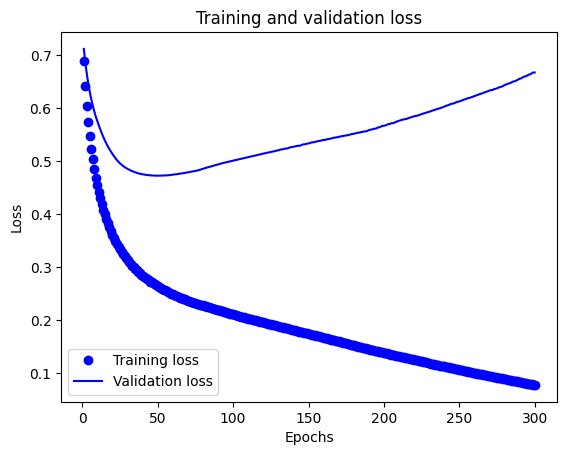

In [37]:
loss_values = history_dict['loss']
val_loss_values = history_dict['val_loss']
epochs = range(1, len(loss_values) + 1)

plt.plot(epochs, loss_values, 'bo', label='Training loss')
plt.plot(epochs, val_loss_values, 'b', label='Validation loss')

plt.title('Training and validation loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.show()

18. Training and Validation Accuracy Plot (Baseline)
This plot shows the training accuracy and validation accuracy over the epochs. Similar to loss, a divergence here suggests the model is performing well on training data but poorly on unseen data (overfitting).

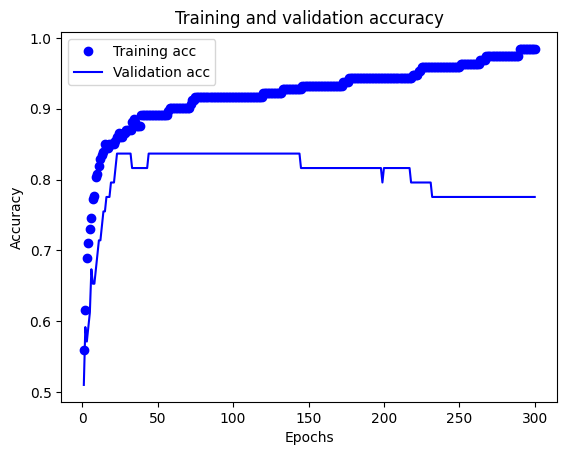

In [38]:
plt.clf()
acc = history_dict['accuracy']
val_acc = history_dict['val_accuracy']

plt.plot(epochs, acc, 'bo', label='Training acc')
plt.plot(epochs, val_acc, 'b', label='Validation acc')
plt.title('Training and validation accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.show()

19. Model Evaluation on Test Set (Baseline)
Finally, the trained model is evaluated on the completely unseen test_X and test_y data to get a final measure of its generalization performance.

In [39]:
model.evaluate(test_X, test_y)

2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 838ms/step - accuracy: 0.8173 - loss: 0.5553


[0.5570360422134399, 0.8196721076965332]

20. Adding Dropout for Regularization

Dropout is a regularization technique where randomly selected neurons are ignored during training. They are 'dropped out' randomly. This means that their contribution to the activation of downstream neurons is temporarily removed on the forward pass, and any weight updates are not applied to the neuron on the backward pass. This helps to prevent overfitting by making the network less sensitive to specific weights and encouraging it to learn more robust features.

In [44]:
# Re-define the model with a Dropout layer
num_colums = train_X.shape[1]

input_layer = keras.layers.Input(shape=(num_colums,))

hidden_layer = keras.layers.Dense(16, activation='relu', name="Hidden")(input_layer)
# Add a Dropout layer after the hidden layer
dropout_layer = keras.layers.Dropout(0.3)(hidden_layer) # 0.3 means dropping 30% of neurons

output_layer = keras.layers.Dense(1, activation='sigmoid', name="Output")(dropout_layer)

model_with_dropout = keras.Model(inputs=input_layer, outputs=output_layer)

model_with_dropout.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 29)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Hidden (Dense)                  │ (None, 16)             │           480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Output (Dense)                  │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 497 (1.94 KB)

 Trainable params: 497 (1.94 KB)

 Non-trainable params: 0 (0.00 B)

In [45]:
# Compile the new model with dropout
model_with_dropout.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

### Re-training with Dropout and Early Stopping

In [46]:
from tensorflow.keras.callbacks import EarlyStopping

# Define the EarlyStopping callback (reusing the same parameters)
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=20,
    restore_best_weights=True
)

print("Re-training the model with Dropout and early stopping...")
history_dropout_early_stop = model_with_dropout.fit(
    train_X, train_y,
    epochs=300,
    batch_size=32,
    verbose=1,
    validation_split=0.2,
    callbacks=[early_stopping]
)

# Get the history for plotting
history_dict_dropout = history_dropout_early_stop.history
loss_values_dropout = history_dict_dropout['loss']
val_loss_values_dropout = history_dict_dropout['val_loss']
acc_dropout = history_dict_dropout['accuracy']
val_acc_dropout = history_dict_dropout['val_accuracy']
epochs_dropout = range(1, len(loss_values_dropout) + 1)

Re-training the model with Dropout and early stopping...
Epoch 1/300
7/7 ━━━━━━━━━━━━━━━━━━━━ 3s 215ms/step - accuracy: 0.4742 - loss: 0.7629 - val_accuracy: 0.5102 - val_loss: 0.7733
Epoch 2/300
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.5134 - loss: 0.7538 - val_accuracy: 0.5306 - val_loss: 0.7413
Epoch 3/300
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.6216 - loss: 0.6638 - val_accuracy: 0.5714 - val_loss: 0.7133
Epoch 4/300
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.6115 - loss: 0.6731 - val_accuracy: 0.5918 - val_loss: 0.6883
Epoch 5/300
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.6482 - loss: 0.6099 - val_accuracy: 0.5714 - val_loss: 0.6666
Epoch 6/300
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.6642 - loss: 0.6067 - val_accuracy: 0.5918 - val_loss: 0.6472
Epoch 7/300
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.6744 - loss: 0.5732 - val_accuracy: 0.6122 - val_loss: 0.6302
Epoch 8/300
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy

### New Training and Validation Loss Plot (with Dropout and Early Stopping)

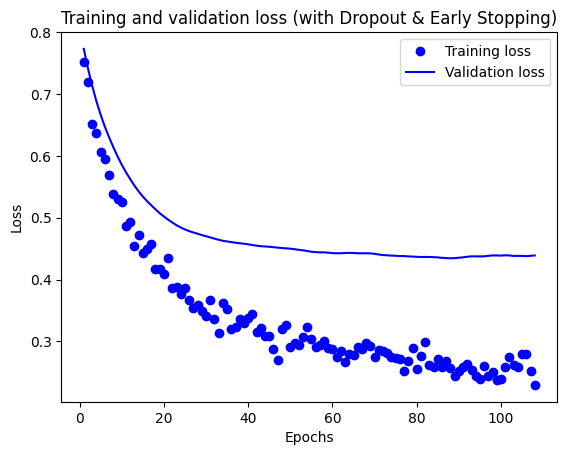

In [47]:
plt.clf()
plt.plot(epochs_dropout, loss_values_dropout, 'bo', label='Training loss')
plt.plot(epochs_dropout, val_loss_values_dropout, 'b', label='Validation loss')

plt.title('Training and validation loss (with Dropout & Early Stopping)')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.show()

### New Training and Validation Accuracy Plot (with Dropout and Early Stopping)

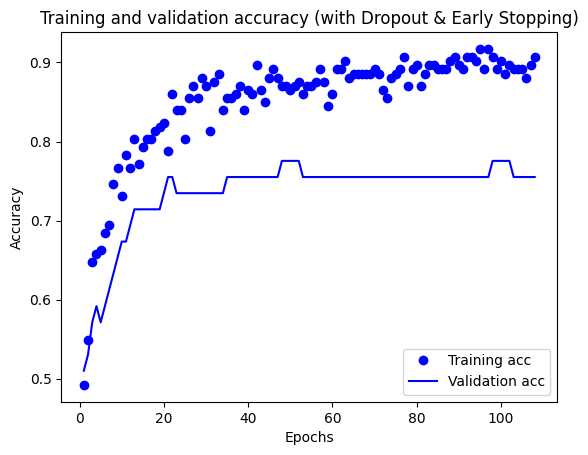

In [48]:
plt.clf()
plt.plot(epochs_dropout, acc_dropout, 'bo', label='Training acc')
plt.plot(epochs_dropout, val_acc_dropout, 'b', label='Validation acc')
plt.title('Training and validation accuracy (with Dropout & Early Stopping)')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.show()

### Model Evaluation on Test Set (with Dropout and Early Stopping)

In [49]:
model_with_dropout.evaluate(test_X, test_y)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 208ms/step - accuracy: 0.8282 - loss: 0.3606


[0.3734856843948364, 0.8360655903816223]